> ✅ **Versión resuelta** (copia de estudio): las preguntas ✍️ y los `COMPLETAR` están respondidos con los valores de `sample_dataset.csv`.

# 4 · Guía de trabajo en equipo — Relaciones entre variables: pairplot y jointplot

> **¿Dónde estamos en el flujo del EDA?**
> Hasta ahora miramos las variables **de a una** (análisis **univariado**: histogramas, boxplots).
> En esta guía pasamos al análisis **bivariado**: ¿cómo se **relacionan dos variables** entre sí? Seguimos en el paso **05 – Explorar y analizar** (relaciones y segmentaciones).
> Teoría relacionada: láminas *"Gráficos de dispersión (scatterplot)"*, *"Tipos de correlación"* y *"La correlación no implica causalidad"*.

> **Pregunta guía del análisis (la misma de los notebooks 0 y 1):**
> ¿Qué características de las células parecen diferenciar un tumor **maligno** (`target = 0`) de uno **benigno** (`target = 1`)?

> **Cómo trabajar**
> 1. Hagan una copia del notebook (*Archivo → Guardar una copia en Drive*) y suban `sample_dataset.csv` al panel **Archivos** (ícono de carpeta, a la izquierda).
> 2. Ejecuten las celdas **en orden** (Shift + Enter).
> 3. Lean los cuadros 📘, completen las celdas 🧩 (reemplazar cada `COMPLETAR`) y respondan en las celdas ✍️.
>    Las celdas 🧩 **dan error hasta que reemplacen `COMPLETAR`**: es esperable, no es un problema del notebook.
> 4. Al final, armen la sección 🎤: **cada equipo va a explicar su notebook al resto del curso en 5 minutos.**
>
> | Ícono | Significa |
> |---|---|
> | 📘 | Concepto (relacionado con la teoría vista) |
> | 💻 | Código listo para ejecutar y observar |
> | 🧩 | Código para completar (reemplazar `COMPLETAR`) |
> | ✍️ | Pregunta para responder en equipo |
> | ⭐ | Extra, solo si les sobra tiempo |
> | 🎤 | Lo que van a presentar al resto |

## 0) Preparación

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns   # seaborn: librería de gráficos estadísticos construida sobre matplotlib

In [2]:
# Cada notebook es independiente: hay que volver a importar librerías y cargar los datos.
# Si aparece FileNotFoundError: el CSV no está subido en el panel "Archivos" de ESTE notebook.
df = pd.read_csv("sample_dataset.csv")
df.shape   # esperamos (569, 31)

(569, 31)

In [3]:
# Creamos una columna con el diagnóstico en palabras: los gráficos se leen mucho mejor
# map() reemplaza cada valor según el diccionario {valor_original: valor_nuevo}
df["diagnostico"] = df["target"].map({0: "maligno", 1: "benigno"})
df["diagnostico"].value_counts()

diagnostico
benigno    357
maligno    212
Name: count, dtype: int64

## 1) Del scatterplot al pairplot

📘 **Concepto.** Un **gráfico de dispersión (scatterplot)** pone una variable en el eje X, otra en el eje Y, y dibuja **un punto por fila**. La forma de la "nube" muestra la relación:

| Forma de la nube | Relación |
|---|---|
| Sube de izquierda a derecha | **positiva** (cuando una crece, la otra también) |
| Baja de izquierda a derecha | **negativa** |
| Nube sin dirección | **nula / débil** |
| Puntos muy pegados a una línea | relación **fuerte** |

Un **pairplot** arma **todos los scatterplots posibles** entre un grupo de variables, en forma de matriz. En la **diagonal** (donde una variable se cruzaría consigo misma) muestra el **histograma** de cada variable.

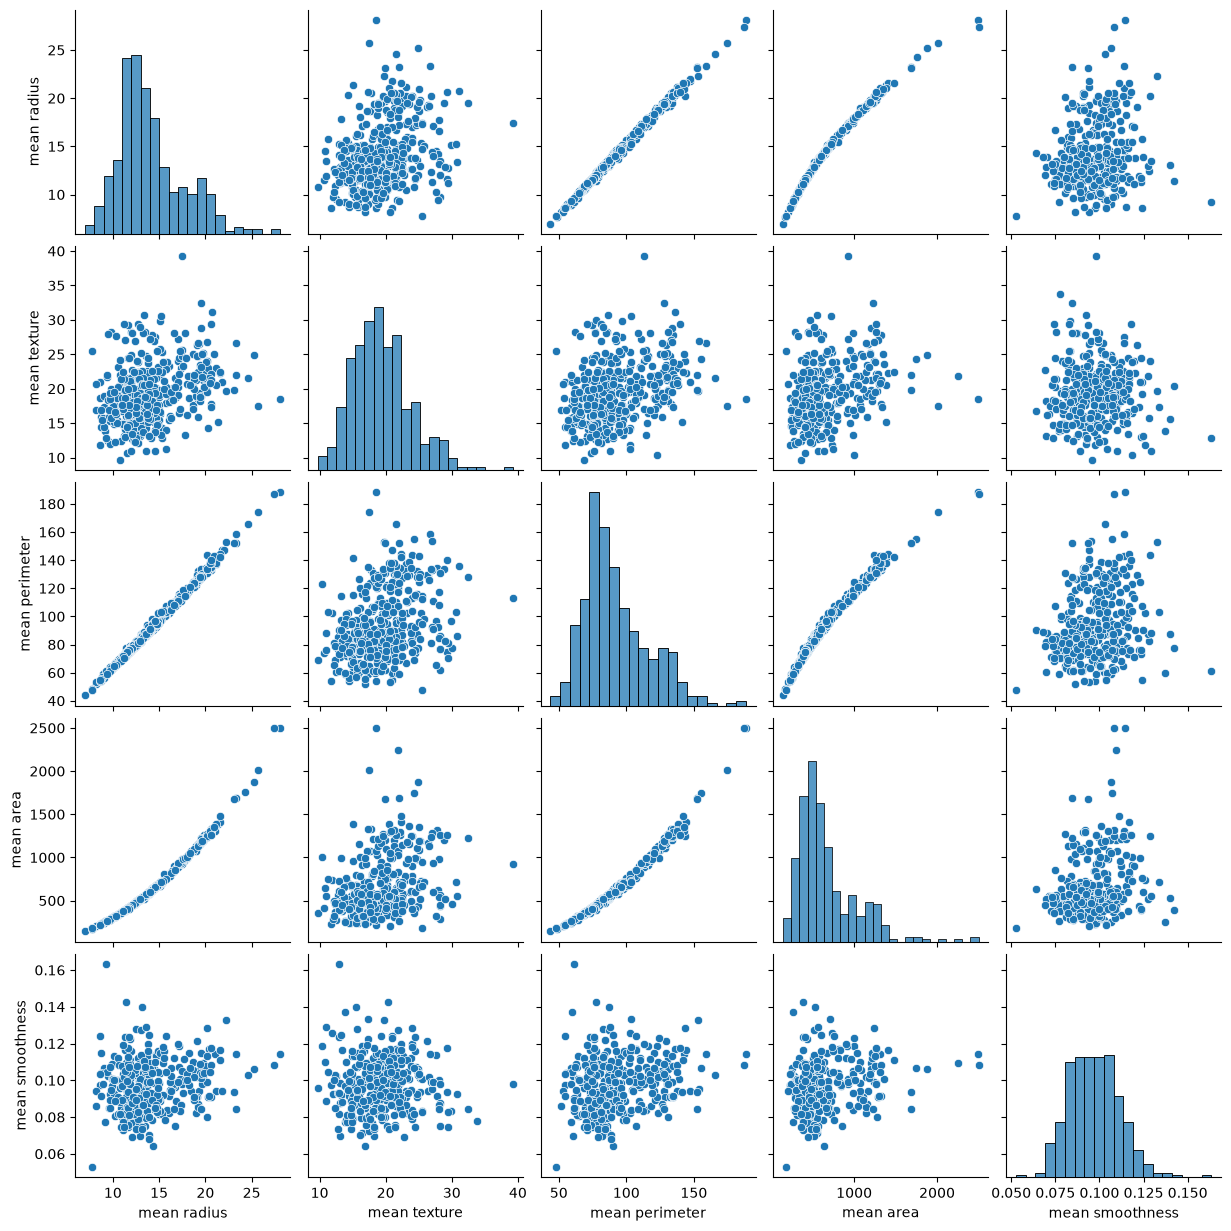

In [4]:
# Usamos solo las primeras 5 columnas: con más, el gráfico se vuelve ilegible (y lento)
sns.pairplot(df.iloc[:, 0:5])
plt.show()

✍️ **Preguntas**
1. ¿Qué pueden decir de la relación entre `mean smoothness` y `mean radius`?
2. ¿Observan lo mismo entre `mean perimeter` y `mean area`?
3. Miren `mean radius` vs. `mean area`: ¿los puntos forman una **recta** o una **curva**? ¿Por qué creen que pasa? (pista: ¿cómo se calcula el área de un círculo?)
4. ¿Qué se repite a ambos lados de la diagonal?

✍️ **Respuesta del equipo:**

1. `mean smoothness` y `mean radius`: la nube no tiene una dirección clara, así que la relación es débil.
2. No, entre `mean perimeter` y `mean area` es una relación positiva y muy fuerte: los puntos están casi pegados a una línea.
3. Entre `mean radius` y `mean area` los puntos forman una curva y no una recta. Creemos que pasa porque el área de un círculo es π por el radio al cuadrado, entonces el área crece más rápido que el radio.
4. A los dos lados de la diagonal se repiten los mismos gráficos, pero con los ejes cambiados.

## 2) Variantes útiles del pairplot

💻 **`corner=True`**: como el gráfico es simétrico, podemos quedarnos con la mitad inferior.

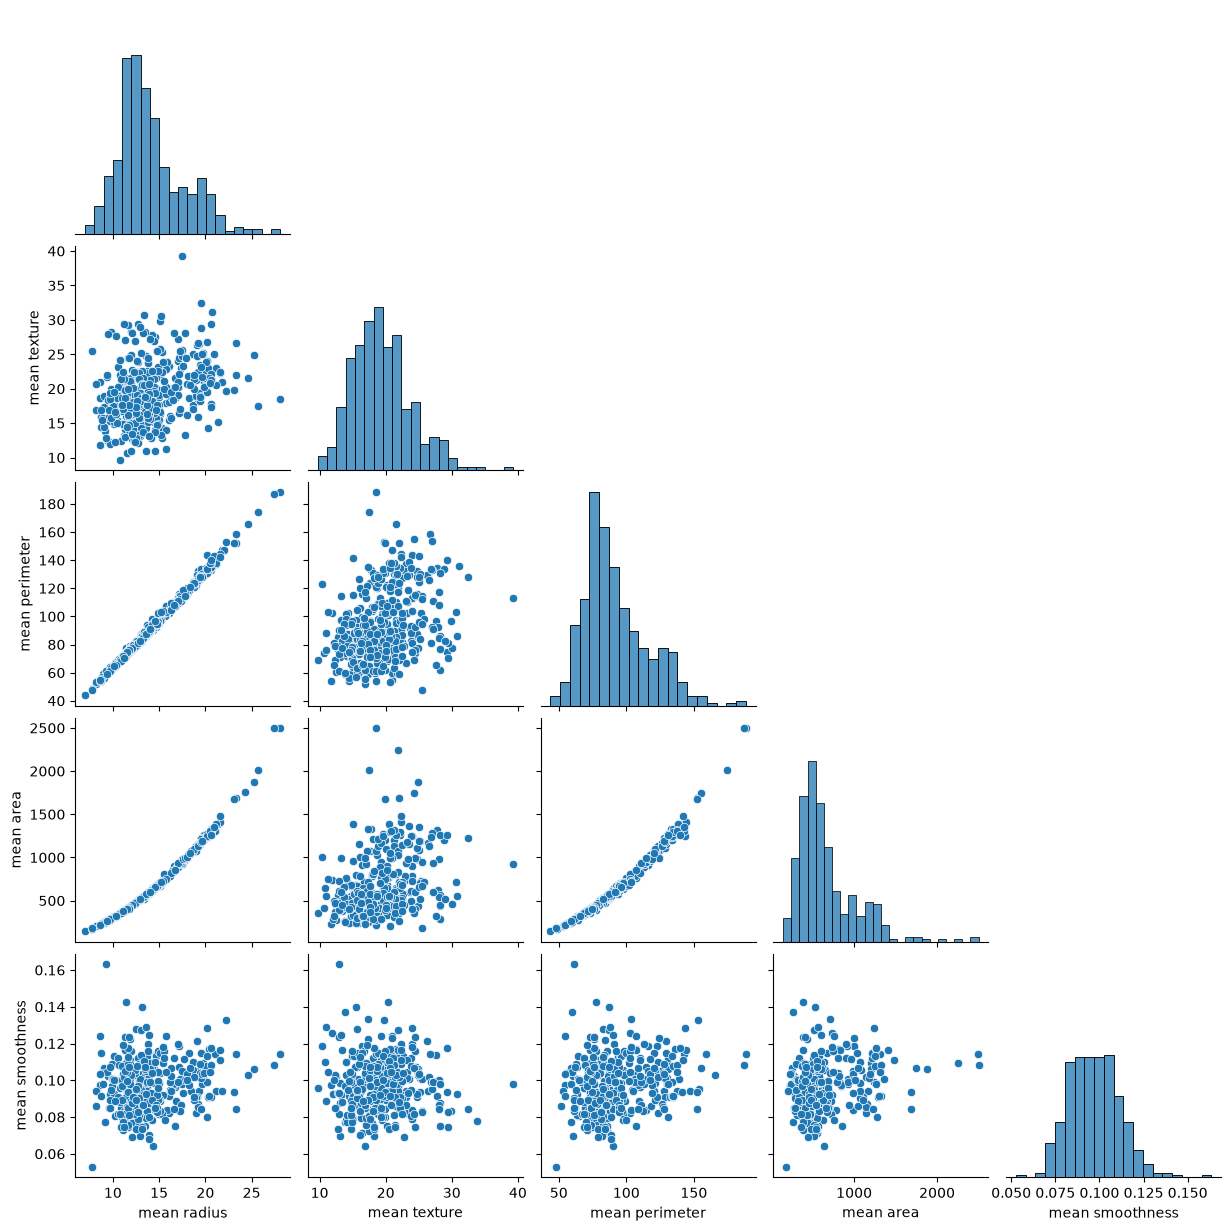

In [5]:
sns.pairplot(df.iloc[:, 0:5], corner=True)
plt.show()

💻 **`kind="hist"`**: en lugar de puntos, dibuja cuadraditos coloreados según **cuántos puntos caen en cada zona**. Útil cuando hay muchos datos y los puntos se tapan entre sí: los cuadrados más oscuros muestran dónde se **concentran** las observaciones.

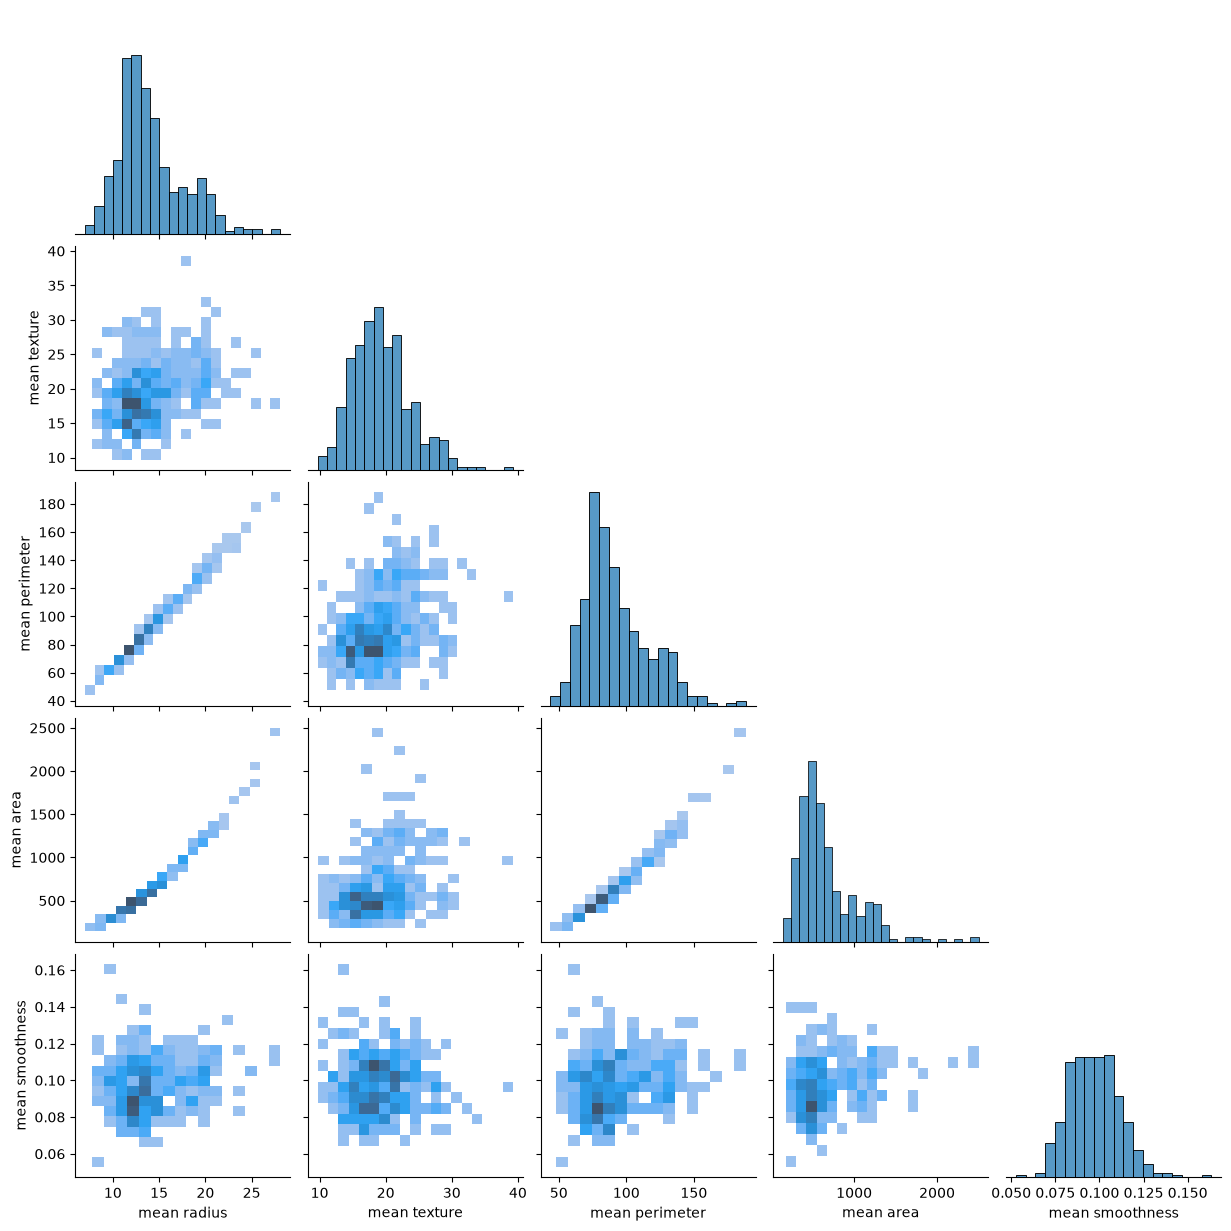

In [6]:
sns.pairplot(df.iloc[:, 0:5], kind="hist", corner=True)
plt.show()

💻 **`x_vars` / `y_vars`**: elegimos exactamente qué variables van en cada eje.

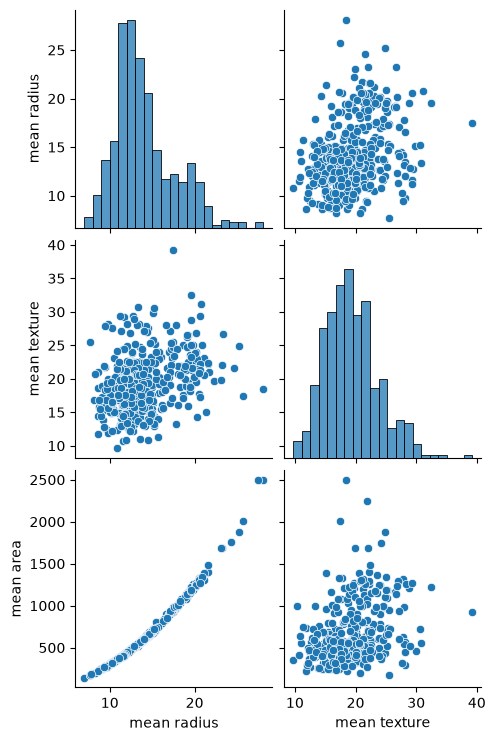

In [7]:
sns.pairplot(df,
             x_vars=["mean radius", "mean texture"],
             y_vars=["mean radius", "mean texture", "mean area"])
plt.show()

## 3) Agregar una tercera dimensión: color por categoría (`hue`)

📘 **Concepto.** Con `hue` pintamos cada punto según una variable **categórica**. Así un gráfico de 2 variables nos muestra 3 cosas a la vez: X, Y y el grupo. Es la herramienta ideal para nuestra pregunta guía: **¿los malignos y los benignos ocupan zonas distintas?**

Con `hue`, seaborn reemplaza los histogramas de la diagonal por **curvas de densidad (KDE)**: una versión "suavizada" y continua del histograma, una curva por grupo.

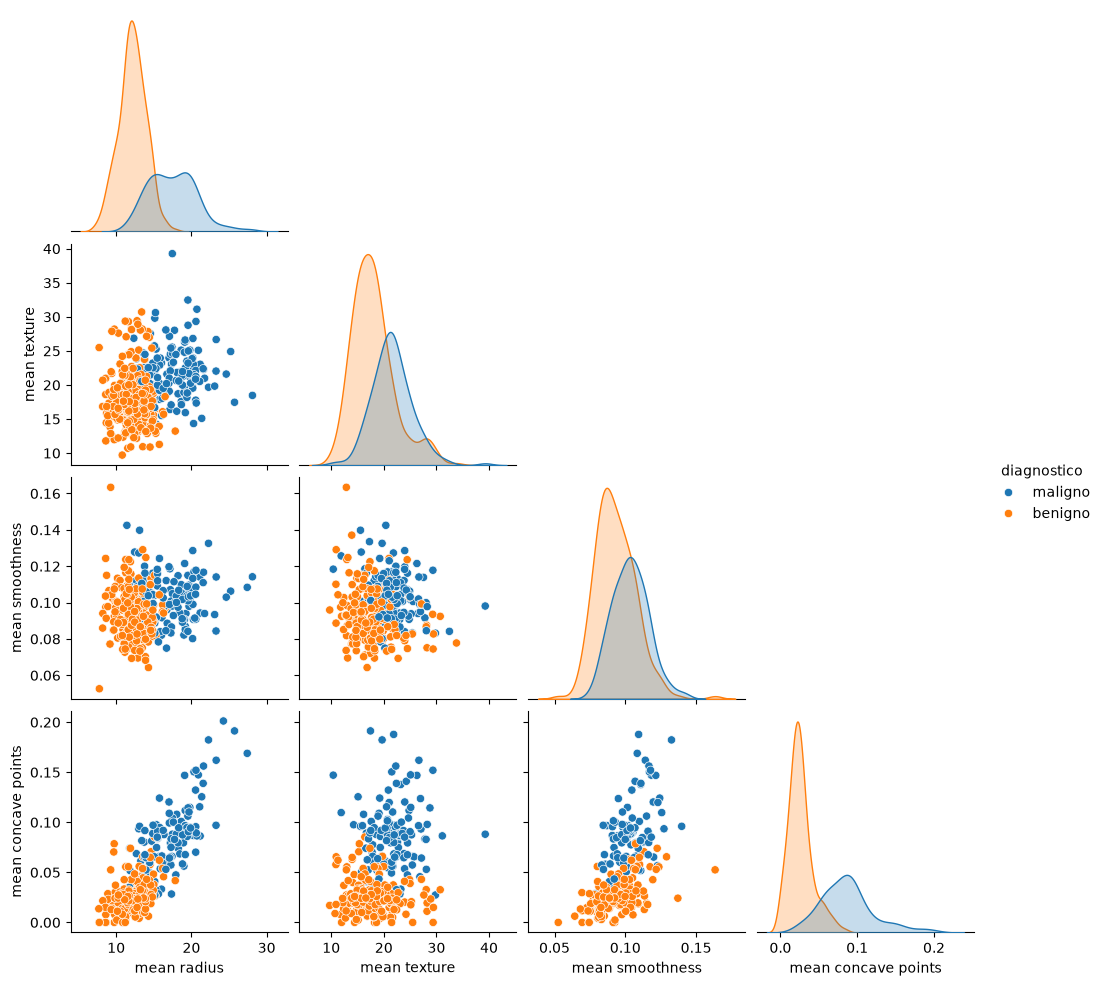

In [8]:
variables = ["mean radius", "mean texture", "mean smoothness", "mean concave points"]
sns.pairplot(df, vars=variables, hue="diagnostico", corner=True)
plt.show()

✍️ **Preguntas**
1. Miren la **diagonal** (curvas KDE). ¿En qué variable las curvas de malignos y benignos están **más separadas**? ¿En cuál se **superponen** más?
2. En los scatterplots, ¿qué combinación de dos variables separa mejor los colores?

✍️ **Respuesta del equipo:**

1. Las curvas más separadas son las de `mean concave points` y `mean radius`. La que más se superpone es la de `mean smoothness`, y después `mean texture`.
2. La combinación que mejor separa los colores es `mean radius` con `mean concave points`: los malignos quedan arriba a la derecha y los benignos abajo a la izquierda.

## 4) Zoom en un par de variables: jointplot

📘 **Concepto.** El **jointplot** muestra **un solo** scatterplot grande y, en los márgenes, la distribución de cada variable por separado. Combina el análisis **bivariado** (centro) con el **univariado** (márgenes).

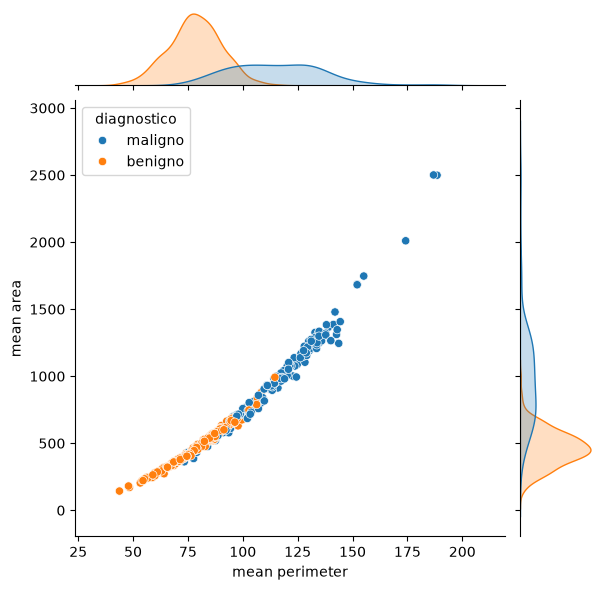

In [9]:
sns.jointplot(data=df, x="mean perimeter", y="mean area", hue="diagnostico")
plt.show()

## 5) 🧩 Tu turno: exploren las variables `worst`

Elijan **4 variables** de esta lista y completen la celda:
`"worst radius"`, `"worst texture"`, `"worst smoothness"`, `"worst compactness"`, `"worst concavity"`, `"worst concave points"`, `"worst symmetry"`, `"worst fractal dimension"`

(Recuerden: `worst` = promedio de los 3 núcleos "peores" de la imagen.)

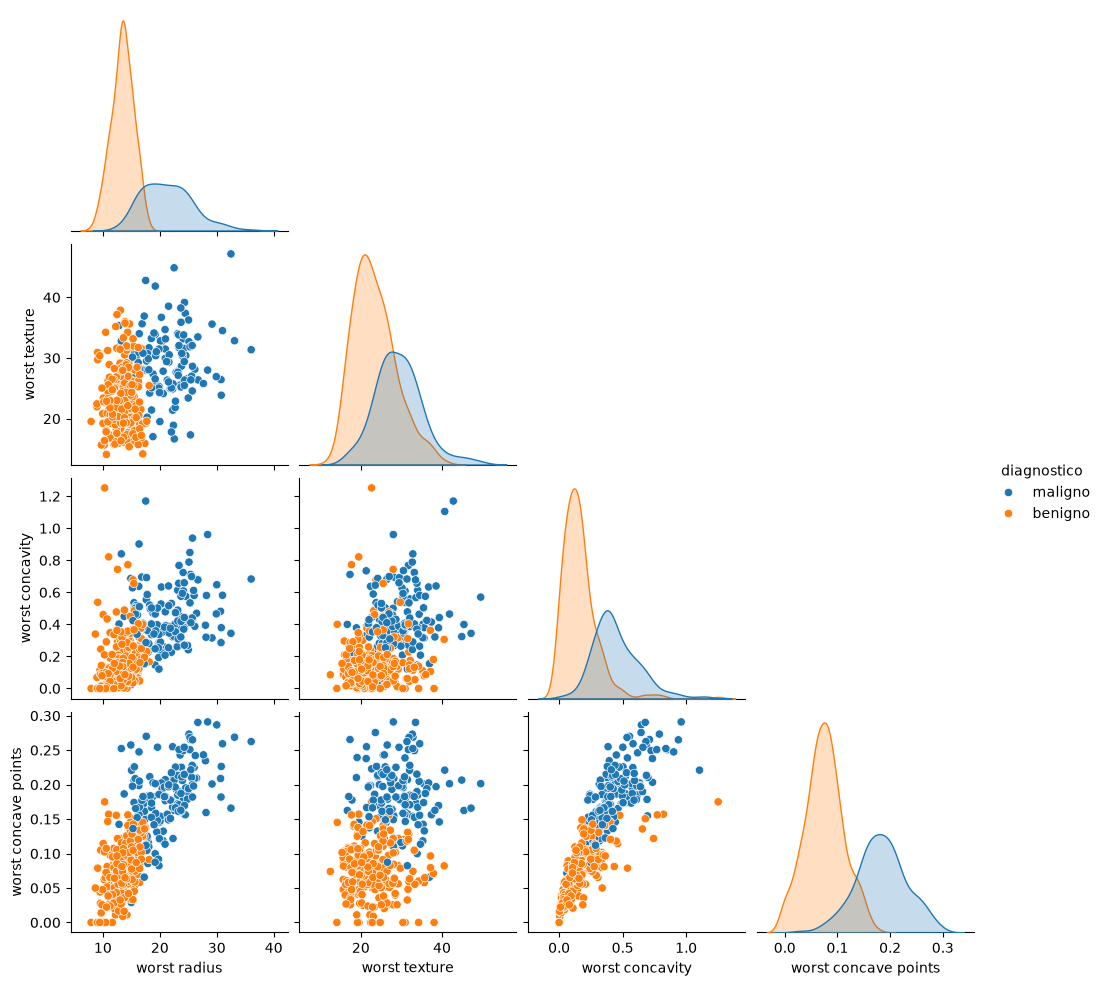

In [10]:
mis_variables = ["worst radius", "worst texture", "worst concavity", "worst concave points"]
sns.pairplot(df, vars=mis_variables, hue="diagnostico", corner=True)
plt.show()

✍️ **Preguntas**
1. Describan **dos relaciones** interesantes que encuentren (dirección y fuerza).


✍️ **Respuesta del equipo:**

Elegimos `worst radius`, `worst texture`, `worst concavity` y `worst concave points`.
1. `worst concavity` y `worst concave points`: relación positiva y fuerte, cuando una sube la otra también (las dos tienen que ver con qué tan irregular es el borde del núcleo).
2. `worst radius` y `worst concave points`: también positiva y bastante fuerte. Además vimos que `worst texture` se relaciona poco con las demás.

## 6) Para pensar: correlación ≠ causalidad

📘 Que dos variables "se muevan juntas" no significa que una **cause** la otra. Puede haber un **tercer factor** que influye en ambas (como la temperatura en el ejemplo de helados y ahogamientos).

✍️ **Pregunta:** `mean perimeter` y `mean area` están fuertemente relacionadas. ¿El perímetro **causa** el área? ¿Qué explica esa relación? ¿Y qué implicancia tiene tener las dos variables en el dataset?

✍️ **Respuesta del equipo:**

No, el perímetro no causa el área. Las dos miden el tamaño de la célula, entonces cuando una crece la otra también, pero lo que explica la relación es el tamaño (el radio) y no que una cause a la otra. Tener las dos en el dataset es redundante porque dan casi la misma información, así que para un análisis o un modelo alcanzaría con una.